## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

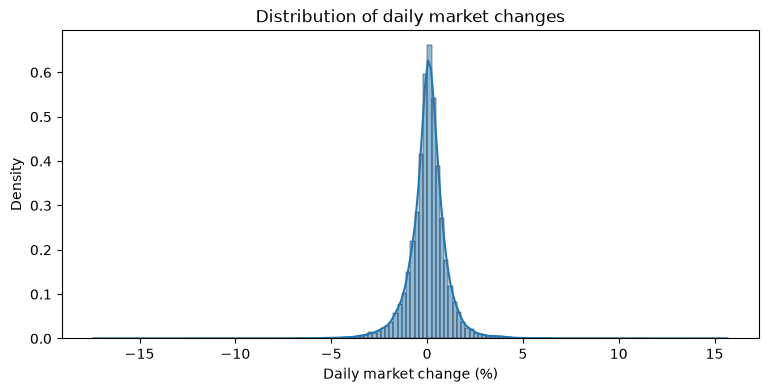

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

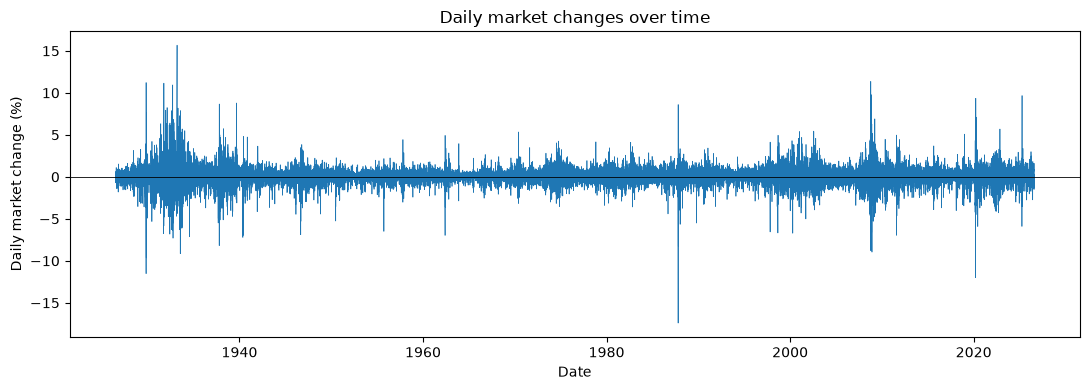

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True,
)

In [6]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [7]:
df[["direction_t","direction_tp1"]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [8]:
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


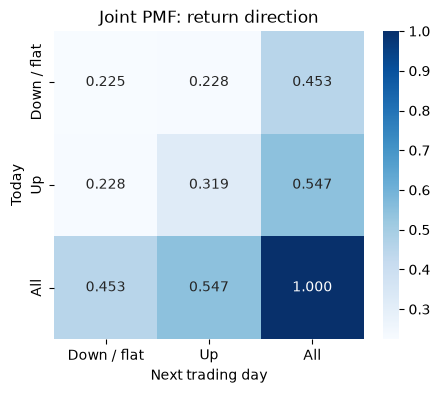

In [9]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [10]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = 'index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 

Up transitions are significantly more common that down transitions. We can see via the heatmap that the the dataset proportions of Up transiions for the next trading day is .547, where the transtions for down/fat for the next trading day is .453.

- Are you more likely to transition to an Up day from a Down or Up day?

The heatmap tells us that you are most likely to transition from an Up day to an Up day compared to a down day. The joint probability of Up-Up is .319, and the Joint Probability of Down-Up is .228.

</div>

In [11]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1,1, np.inf], labels = return_categories)


In [12]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [13]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [14]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize = True, margins = True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)

Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759

- Which are the most or least common?

The most common is small gain having 9785 observations, which is leading across the bins significantly with a proportion of .372 in the dataset. The least common is large loss, containing 2759 observations with a proportion of .105 in the dataset.
  
  </div>

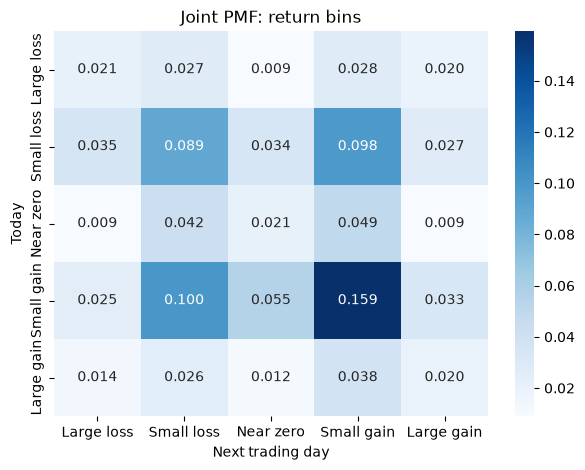

In [15]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

It appears as if the transition that is most likely to occur is the small gain transition. In the heatmap, it is the category with the darkest hue across the categories, which signifies a higher proportion within the dataset.

The second transition that is most likely to occur is the small loss transition. This is because, in the heatmap, it has the second darkest hue and the second highest join proportions across the board.

</div>

In [16]:
#conditional PMF 
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


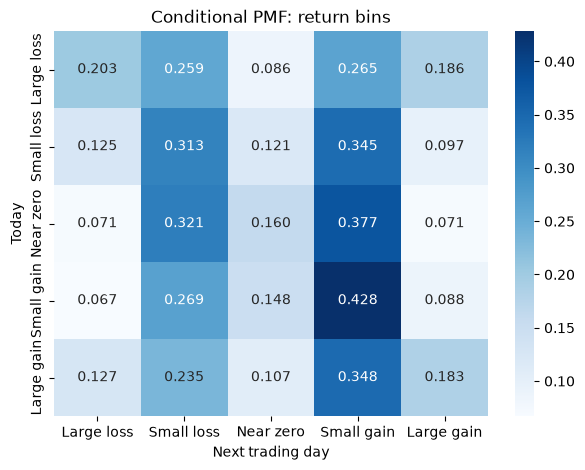

In [17]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize="index"),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 

Large Loss- Small Loss (.259) & Small Gain(.265).

Small Loss- Small Gain(.345) & Small Loss (.313).

Near Zero- Small Gain(.377) & Small Loss (.321).

Small Gain- Small Gain (.428) & Small Loss(.269)

Large Gain- Small Gain(.348) & Small Loss (.235)

- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 

Subjectively speaking, some rows are closer than others to a uniform mass function with a probability .2 over each transition. 

- Large Loss- Close
- Small Loss- Not Close
- Near Zero- Not Close
- Small Gain- Not close
- Large Gain- Closer, but not as close as large loss

It appears that the extreme gains/losses are closer than the other outcomes to a uniform mass probability.

- Is it relatively easy or difficult to predict the next state?

I would say it is relatively difficult to predict the next state. This is because the probabilities are sparse for each transition. There is no categories being **dominated** by a particular transition in the next day. Small gains and Small Losses are the most prevelant, but I would not say that they dominate the probability fields.

</div>

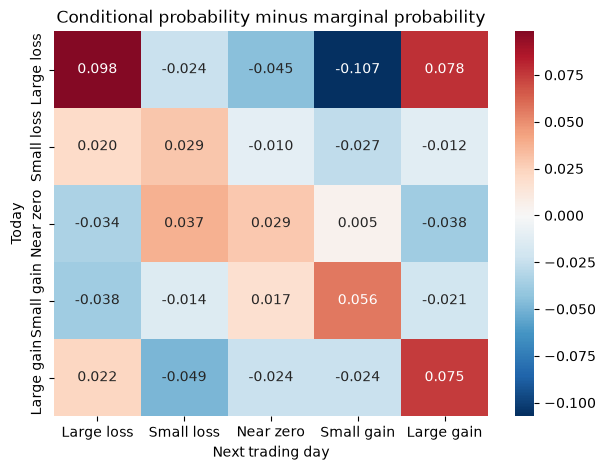

In [18]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
next_state_pmf

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index")
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(conditional.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?

The transitions that are more likely than independence predicts are:

    Nero Zero: Probability has the reddest hue across the transitions, which implies that is is more likely than independece suggests.

    Small Loss: Probability that has the second reddest hue across the board, which additional implies that is more likely than independence suggests.

    It is worth to mention that Large Loss is often precedeted by either a Large loss and Large Gain. The hue of each of these tiles extremely red, which suggest that these transitions are more likely than independce suggests. The same goes with Large Gain, which is more likely followed by a Large Gain than independence suggests.


- Does knowing today's state change the forecast for tomorrow?

Yes, the heatmap suggets that knowing todays state changes the forecast for tommorow. The whole point of the heatmap is to show us that gains are not independent and in a silo, and are often related to what occured the day prior. The most prevelant example is this is with Large Gains and Losses, which exemplify this notion the best.


- How is this comparison different from comparing each row to a uniform PMF with probability .2?

This comparison is fundamentally different than comparing each row to a uniform PMF with probability .2. A uniform PMF with probability .2 assumes that all outcomes are equally likely, which is not true in this and most cases. This comparison shows, between the conditional and marginal pmf's, that there is often more factors  just overall frequencies when determining a likely outcome for tommorow. This comparison shows us that outcomes today are often preceded by outcomes tommorow, which is a fundemental trend in my opinion when analyzing time series data. 

</div>

In [19]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby("y_t")["market_return_pct_tp1"].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 

The expected returns for tommorow are the means of each of the current states.

Large loss=−0.0383%
Small Loss=−0.0438%
Near Zero=0.0150%
Small gain=0.1068%
Large Gain=0.1631%

- How do the min and max values for tomorrow vary across states? 

It appears the extreme values like mins and maxes are more extreme for Large Losses, Small Losses, and Large Gains. These current states contain the lowest minimum returns, while simulateonusly containing the highest maximum returns. Tommorow's Return in comparison for Near Zero and Small Gain returns today are small in comparison.

- Which states have the highest standard deviation for tomorrow's percent returns? 

The states that have the highest standard deviation for tommorow's percent retutns are the Large Losses, Small Losses, and Large Gains, the values that also contain the most extreme,extreme values.

- Describe any patterns in the volatility you notice.

It appears that small gains and near zero returns are often precceded by less volatile returns tommorow. They both contain a below 1% standard deviation return. The states that have the highest standard deviation for tommorow's percent retutns are the Large Losses, Small Losses, and Large Gains, the values that also contain the most extreme,extreme values. This makes me believe that these standard deviations are most likely influenced by such extreme-extremes, which makes me interested to see more robust standard deviations.

</div>


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [43]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame()

df

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,direction_t,direction_tp1,return_bin,y_t,y_tp1,market_return_pct_tp1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up,Near zero,Q11,Q16,0.46
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up,Small gain,Q16,Q12,0.18
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up,Small gain,Q12,Q11,0.10
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Up,Up,Near zero,Q11,Q13,0.23
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Up,Down / flat,Small gain,Q13,Q4,-0.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26291,2026-07-27,2026,7,2026-07-01,18,0.15,0.02,0.17,0.17,Up,Up,Small gain,Q12,Q14,0.29
26292,2026-07-28,2026,7,2026-07-01,19,0.27,0.02,0.29,0.29,Up,Down / flat,Small gain,Q14,Q2,-1.50
26293,2026-07-29,2026,7,2026-07-01,20,-1.52,0.02,-1.50,1.50,Down / flat,Up,Large loss,Q2,Q21,1.61
26294,2026-07-30,2026,7,2026-07-01,21,1.59,0.02,1.61,1.61,Up,Up,Large gain,Q21,Q18,0.70


In [21]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

<Axes: xlabel='y_tp1', ylabel='y_t'>

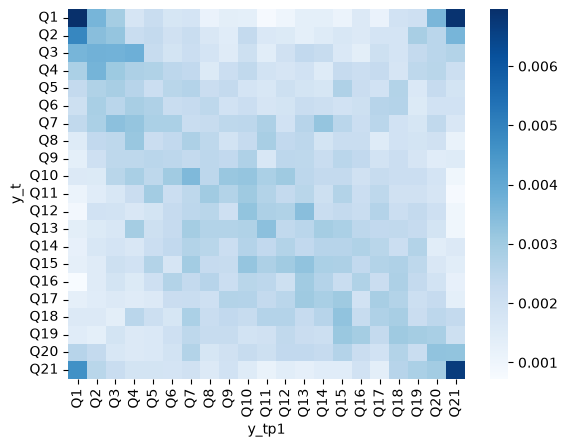

In [22]:
sns.heatmap(quantile_joint, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

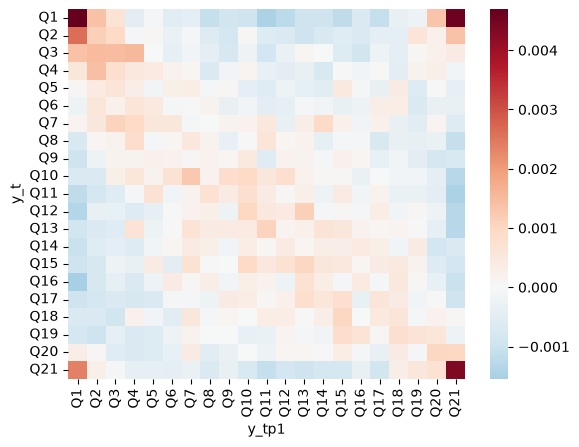

In [23]:
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

In [24]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

It appears that most of the quantiles are in the same bin as tommorows quantile, denoted by the diagonal line running through the heatmap. This that same bin quantiles occur more across consecutive days than the uniform pmf suggests. We can also see the red diagonal line being surrounded by a sea of blue hue. This suggests that different bin quantiles are less likely than the value the uniform pmf suggests.

It is also noteworthy to mention the 4 values on the corner being **extremely** likely compared to what the uniform pmf suggests. These imply that these transitions occur way more than the baseline being set by the uniform pmf, which futher explains that extremes can better predicts extremes.

</div>

<Axes: xlabel='y_tp1', ylabel='y_t'>

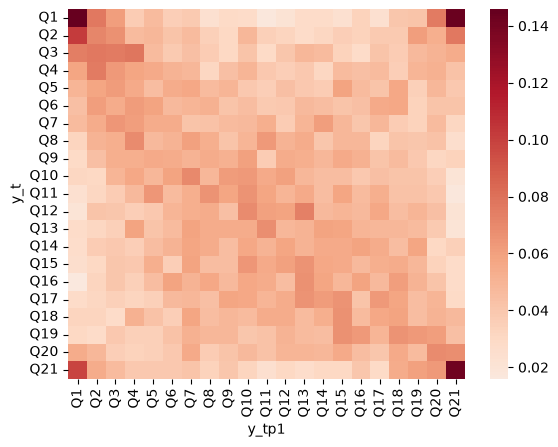

In [39]:
# compute and plot the conditional
#Conditional PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_cond = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize='index'
)

sns.heatmap(quantile_cond, cmap='RdBu_r', center=0)

<Axes: xlabel='y_tp1', ylabel='y_t'>

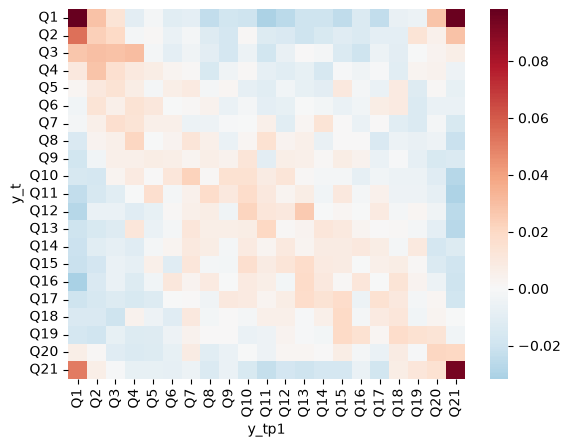

In [38]:
sns.heatmap(quantile_cond-1/21, cmap='RdBu_r', center=0)

In [ ]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.


<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

For the normal conditional pmf heatmap, no. It looks exactly like the other heatmaps.

For the normalization away from the unifrom PMF heatmap,I see pretty much the same patterns from what I analyzed from the join pmf heatmap. It appears that conditional probabilities are more likely to stay in the same bin from one day to the next compared to tranisitioning to another bin, compared to what the uniform pmf suggests. The intepretation is given the bin today, the bin tommorow is most likely to say in the same quantile than what the uniform PMF suggests.

</div>

In [47]:
# compute the next day's min, mean, and max conditional on each bin

df['return_tp1'] = df['market_return_pct'].shift(-1)

next_day_stats = df.groupby('y_t', observed=False)['return_tp1'].agg(
    ['min', 'mean', 'max','std']
)

display(next_day_stats)

,min,mean,max,std
y_t,,,,
Q1,-17.41,-0.013713,11.22,2.140465
Q2,-7.36,-0.076712,6.36,1.285882
Q3,-8.79,-0.097084,11.36,1.227976
Q4,-8.28,-0.058594,6.16,1.049607
Q5,-6.89,-0.024211,4.56,0.989470
Q6,-11.23,-0.022692,6.37,1.024761
Q7,-3.94,-0.030241,7.37,0.930389
Q8,-3.40,-0.014303,4.76,0.835663
Q9,-6.00,0.025860,5.49,0.853220


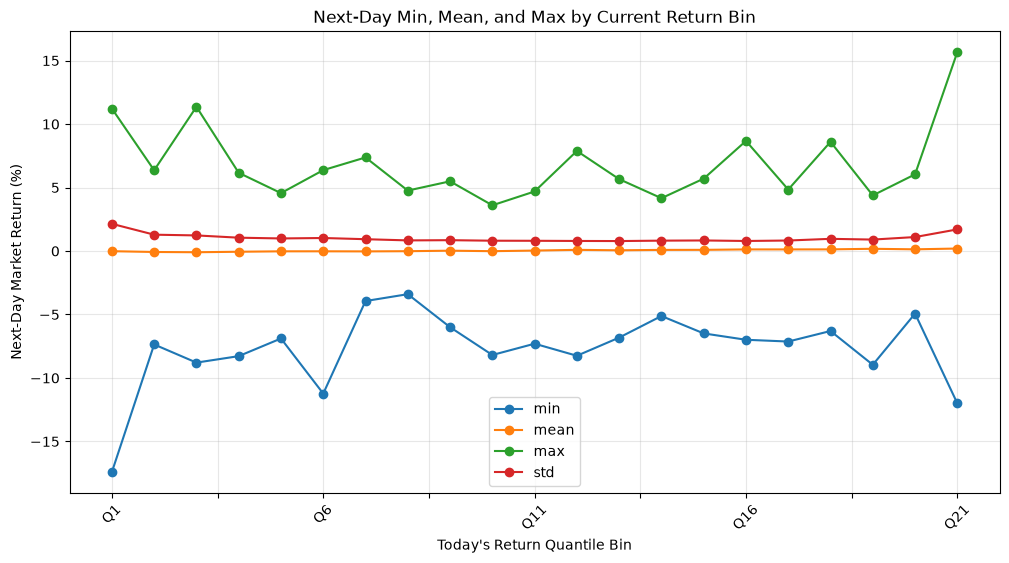

In [48]:
#plot as lines on a graph against the bins
next_day_stats.plot(figsize=(12, 6), marker='o')

plt.xlabel("Today's Return Quantile Bin")
plt.ylabel("Next-Day Market Return (%)")
plt.title('Next-Day Min, Mean, and Max by Current Return Bin')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

It appears that the min's and maxes are much more extreme at quantile 1 and quantile 21. Besides that, the mins and maxes appear to fluctuate but have no distinct relationship with one another outside of those two bins. The mean remains stable at a near zero next day return. This suggests, on average, that a return for tommorow is close to zero despite what bin it is placed in. It also suggests that there is little relationship between the bin and tommorows return for the mean remains nearly constant across all the nears 

</div>

In [29]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

The standard deviation remains relatively stable across all the bins. It does, however, jump a little near bins 1 and 21, most likely due to influence from outliers in the dataset. This suggests that there is greater variability in next day returns when the bin, the first day, is an extreme value itself.The standard deviation remaining constant outisde of that suggests that the variability in tommorows return also has little to do with what bin it is placed in, exemplfying the notion that the market is difficult to predict.

</div>

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?


It is incredibly easy. I am just doing data science for fun. Jokes aside, predicting the market is incredibly difficult. We have been shown today that returns are often sparactic and sparsely distributed, which makes a concrete prediction difficult to formulate. I personally would not feel confident in predicting the market with everything I have seen in the lab. It appears as if the market is so wide and broad with all the factors that contribute to it that not even the market can predict itself, as we saw with the bins.


</div>